In [9]:
import pandas as pd

df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


The "Telco Customer Churn" dataset contains 21 columns and 7043 rows.

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

None of the features contain null values. "SeniorCitizen", "tenure" and "MonthlyCharges" are numeric while all the other features are strings (categorical). "TotalCharges" are of the type string instead of numeric values.

In [11]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
# "coerce" tells pandas to convert any invalid value to NaN
print(df["TotalCharges"].isna().sum())
df[df["TotalCharges"].isna()][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


After converting all "TotalCharges" to numeric form we find 11 rows without any data. All these rows contains 0 as tenure meaning they're new customers meaning they haven't been charged yet.

In [12]:
print(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df["customerID"].duplicated().sum())

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64
Duplicate rows: 0
Duplicate IDs: 0


No other missing values apart from the "TotalCharges" of new customers mentioned earlier. Handling of duplication values isn't required either.

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


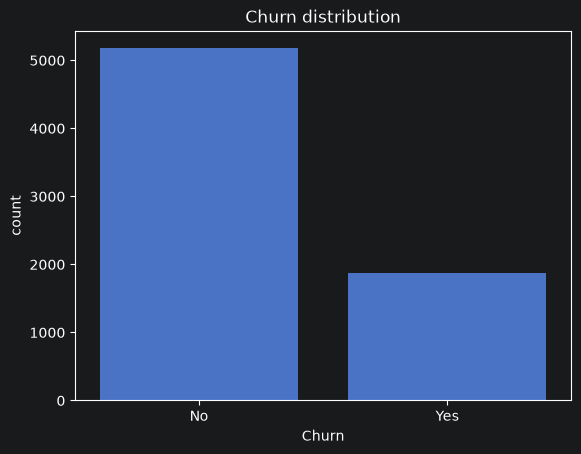

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True).round(3))

sns.countplot(data=df, x="Churn")
plt.title("Churn distribution")
plt.show()

5174 customers stayed while 1869 left. When taken as a proportion trimmed to three decimals, 0.735 (73.5%) stayed while, 0.265 (26.5%) left. The fact that the distribution is not balanced should be taken to consideration as it affects accuracy in the following steps. (for an example a model predicting "No" for everything will have an accuracy of 73.5%)

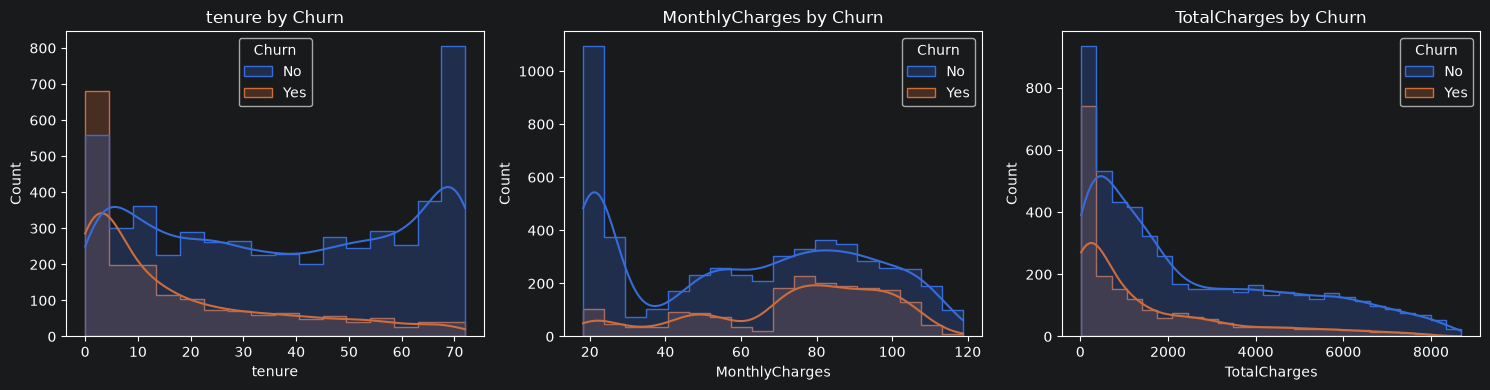

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.425,1683.60
Yes,10.0,79.650,703.55


In [14]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"] # list of numeric columns to be examined

fig, axes = plt.subplots(1, 3, figsize=(15, 4)) # defines canvas with three plots
for ax, col in zip(axes, num_cols): # loops through each numeric column creating respective visualization
    sns.histplot(data=df, x=col, hue="Churn", kde=True, element="step", ax=ax) # draws the histogram for each column, splitting data by color based on whether they churned or not, adding smooth curve using 'kde', and making sure both groups are visible irrespective of them overlapping or not using "step"
    ax.set_title(f"{col} by Churn")
plt.tight_layout() #adjusts the spacing between the plots
plt.show()

df.groupby("Churn")[num_cols].median()

The histograms show that churners have shorter tenure, customers on cheaper plans are less likely to churn and churners have lower total charges, but this is likely a consequence of shorter tenure.

These values are to be scaled accordingly as they have very different ranges ("tenure" from 0 to ~70 vs "TotalCharges" from 0 to ~8,000) as KNN and Logistic Regression are sensitive to feature scale.

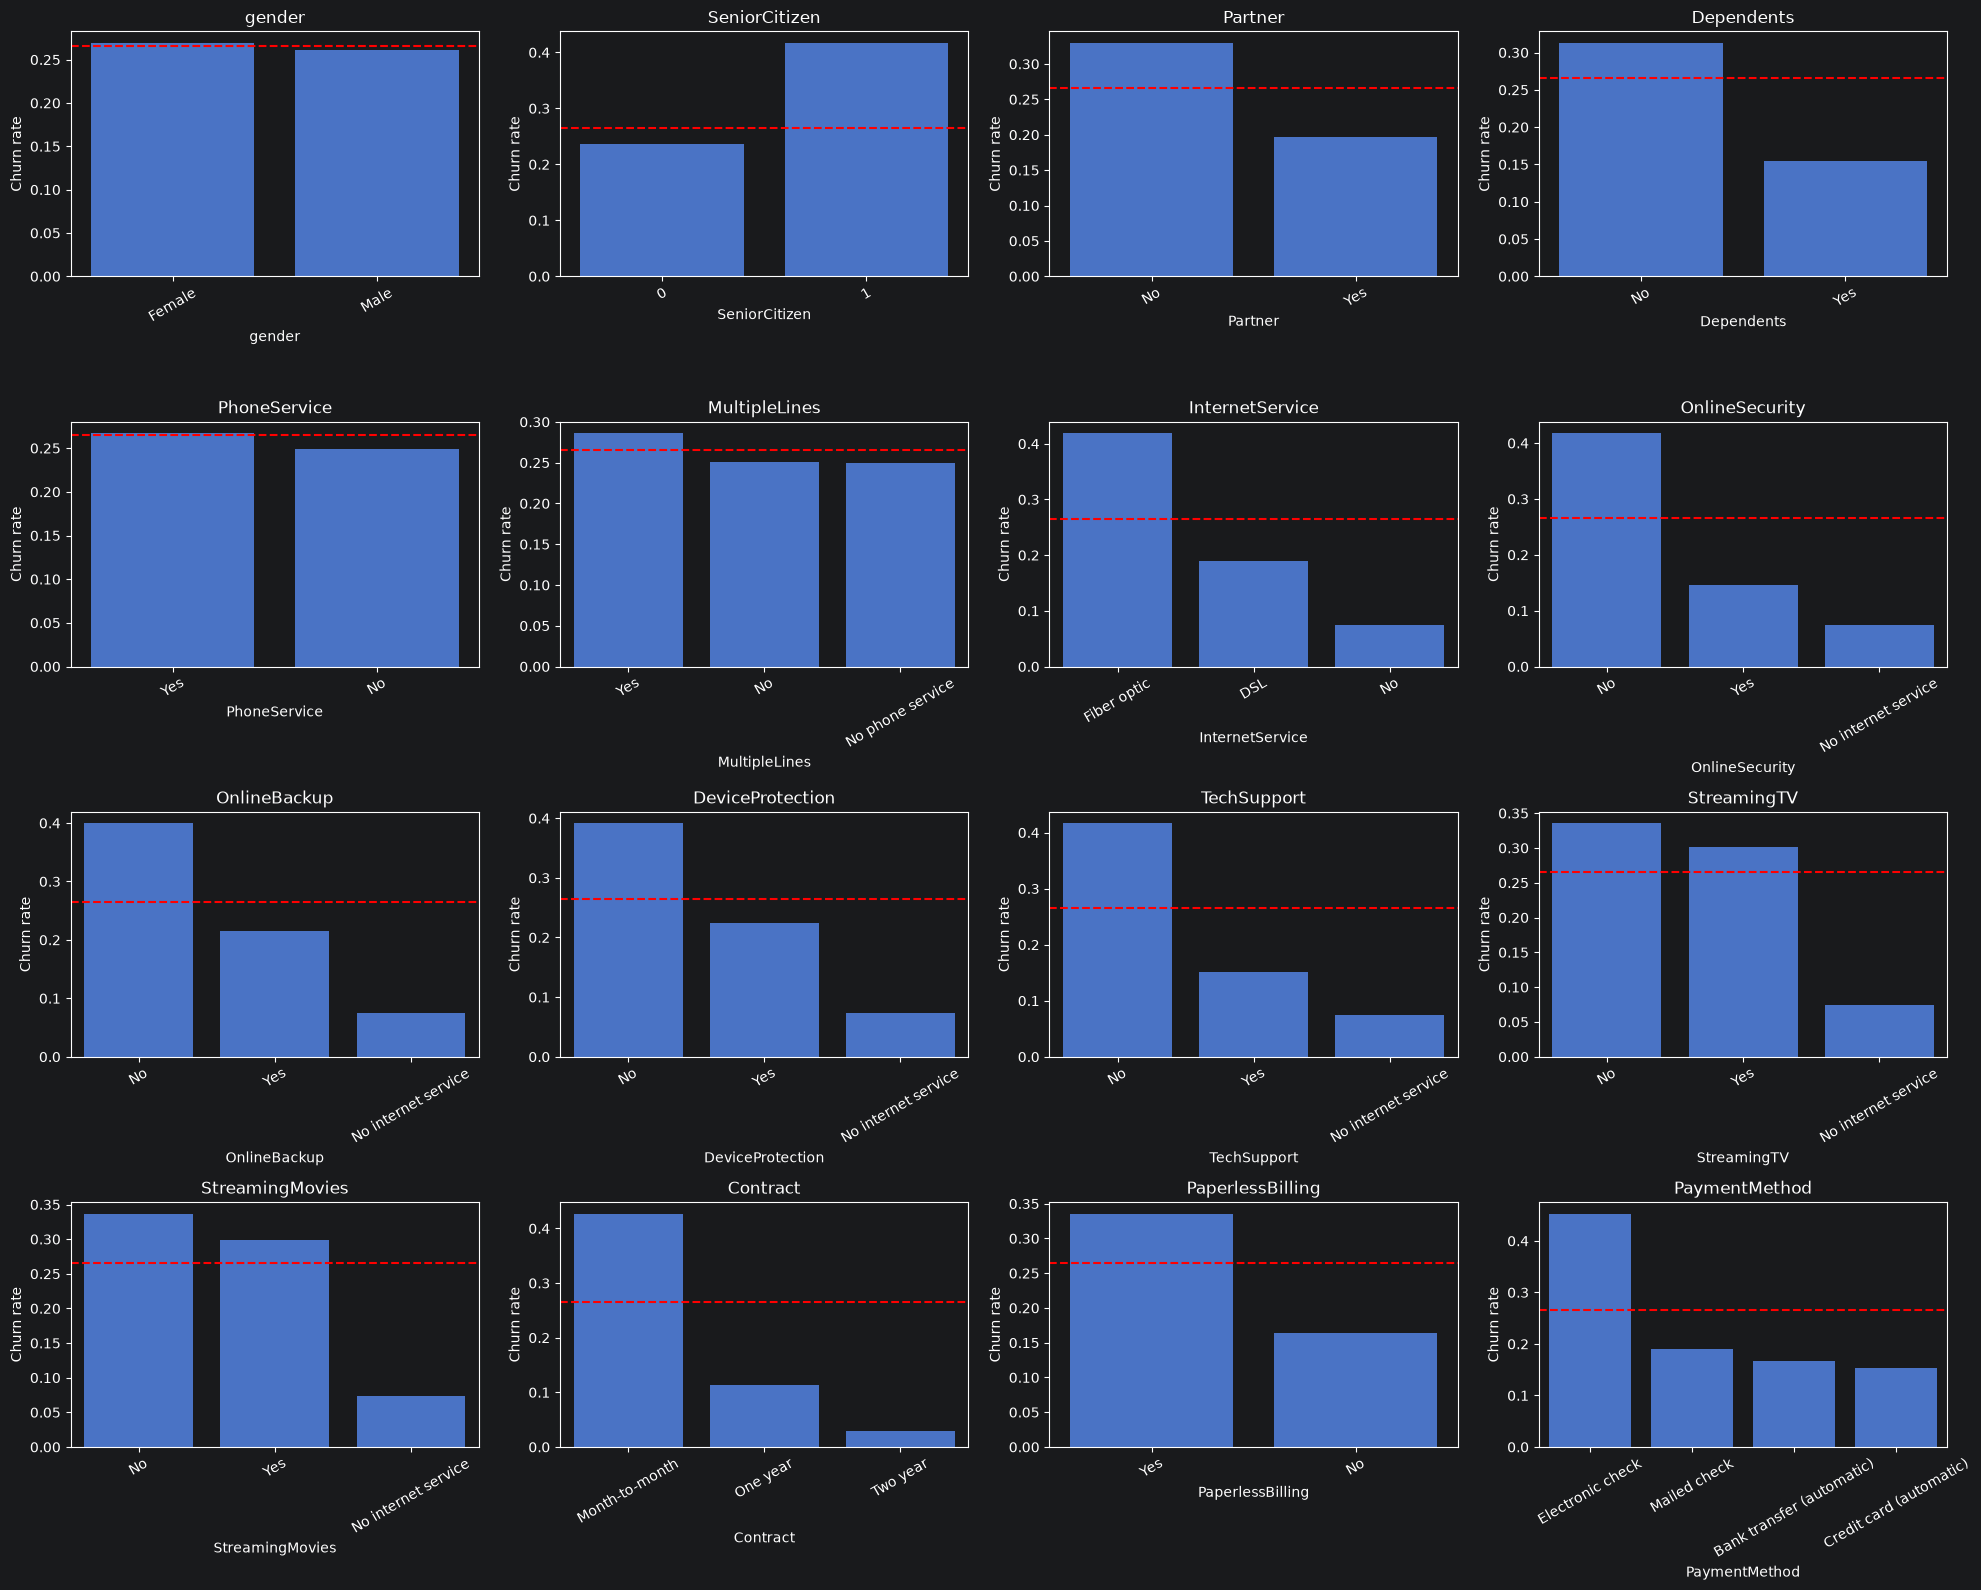

In [15]:
cat_cols = [c for c in df.columns if c not in num_cols + ["customerID", "Churn"]] # list of categorical columns to be examined excluding "customerID" and "Churn"
overall = (df["Churn"] == "Yes").mean() # calculates average churn rate

fig, axes = plt.subplots(4, 4, figsize=(20, 16)) # defines canvas with sixteen plots
for ax, col in zip(axes.flat, cat_cols):
    rate = (df["Churn"] == "Yes").groupby(df[col]).mean().sort_values(ascending=False) # calculates how many churned in each group
    sns.barplot(x=rate.index, y=rate.values, ax=ax) # draws bar chart for each category
    ax.axhline(overall, color="red", linestyle="--") # marls average churn for each chart
    ax.set_title(col)
    ax.set_ylabel("Churn rate")
    ax.tick_params(axis="x", rotation=30) #ensures labels don't overlap
plt.tight_layout()
plt.show()

"Contract" is the strongest categorical indicator showing that customers with no long term plans leave more often. Those with fiber optics seem to churn more than other "InternetService"s. Electronic check users churn about double the other methods. Customers without "TechSupport" or "OnlineSecurity" seem to churn more. Similarly senior citizens and customers without dependents churn more whereas "gender" doesn't seem to have a major effect.

 All these features will require encoding as they are categorical text.

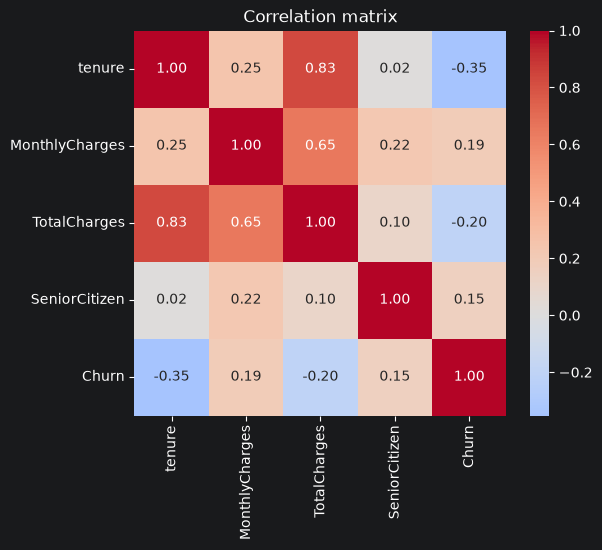

In [19]:
df_corr = df.copy()
df_corr["Churn"] = (df_corr["Churn"] == "Yes").astype(int) # converts "Churn" to 1/0 so it can be correlated

corr = df_corr[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "Churn"]].corr() #create correlation matrix

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", center=0) # draws a correlation matrix as a color based grid, where 'annot' writes the values inside each cell, and center tells seaborn that the middle of the color scale is 0
plt.title("Correlation matrix")
plt.show()

"tenure" has a negative correlation with "Churn" meaning customers who stay longer are less likely to leave. "MonthlyCharges" has a weak positive correlation meaning customers who pay more churn slightly more. "TotalCharges" and "tenure" are strongly correlated because total charges accumulate over time. "TotalCharges" is also correlated with "MonthlyCharges". This is multicollinearity because "TotalCharges" mostly repeats information already in "tenure" and "MonthlyCharges".

Logistic Regression can become unstable when features are highly correlated. Random Forest is not as much as affected by correlated features.
